Plan:

Load file

Apply crop

Apply sobel

Turn red

Recombine

???

Profit

Yeah, no so that didn't happen. What happened instead was that it turned out that the canny filter was really good at detecting lines, which we then narrowed down with hough lines. tv or bilateral blur was used to reduce noise. But you essentially average out the lines and it jus kinda works.


In [1]:
import skimage as ski
import os 
import numpy as np
from PIL import Image
from scipy.fft import fft2, fftshift

from skimage.restoration import (
    denoise_tv_chambolle,
    denoise_bilateral,
    denoise_wavelet,
    estimate_sigma,
)

import matplotlib.pyplot as plt


In [2]:
def get_file(num):

    filename = os.path.join('.', 'imgs', f'00{num}.tif')
    img=ski.io.imread(filename)
    return img
    

In [3]:
def disp(img):
    display( Image.fromarray(np.uint8(img)).convert('RGB'))

def disp_float(img):
    img = to_u8(img)
    display( Image.fromarray(np.uint8(img)).convert('RGB'))

def disp_bool(img):
    display( Image.fromarray(np.bool(img)).convert('RGB'))

def to_u8(img):
    return ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)

In [18]:
img1 = get_file(1)
imgs = [get_file(i).astype(np.uint16) for i in range(1,30)]

NameError: name 'get_file' is not defined

(426, 428, 4)


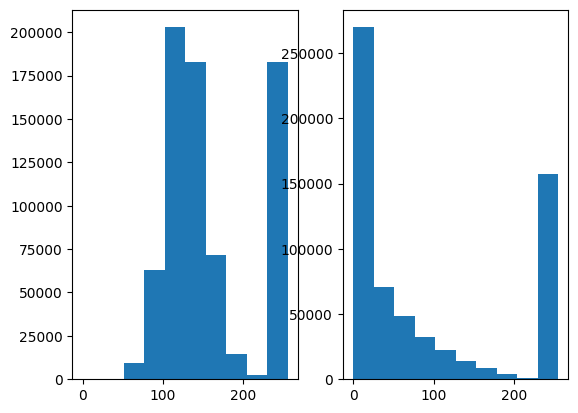

In [8]:
before = os.path.join('.', 'before.png')
after = os.path.join('.', 'after.png')

img_b=ski.io.imread(before)
img_a=ski.io.imread(after)

fig, ax = plt.subplots(1,2)
ax[0].hist(img_b.flatten())
ax[1].hist(img_a.flatten())

print(img_b.shape)

In [3]:
img_b_avg = np.average(img_b.flatten())
img_a_avg = np.average(img_a.flatten())

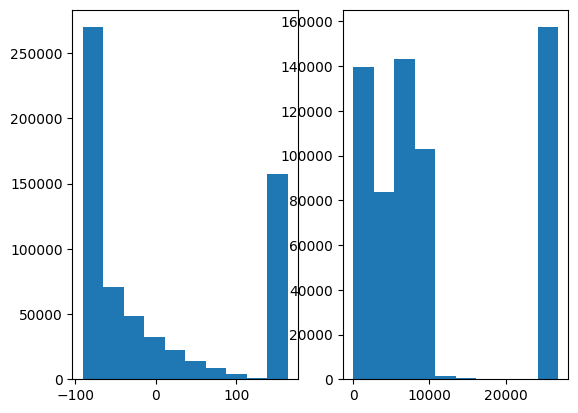

In [ ]:
import math

img_b_diff = img_b.flatten() - img_b_avg
img_a_diff = img_a.flatten() - img_a_avg

fig, ax = plt.subplots(1,2)

ax[0].hist(img_a_diff)
ax[1].hist(img_a_diff**2)

b_sum = np.sum(img_b_diff**2) / (img_b.shape[0] * img_b.shape[1])
a_sum = np.sum(img_a_diff**2) / (img_a.shape[0] * img_a.shape[1])

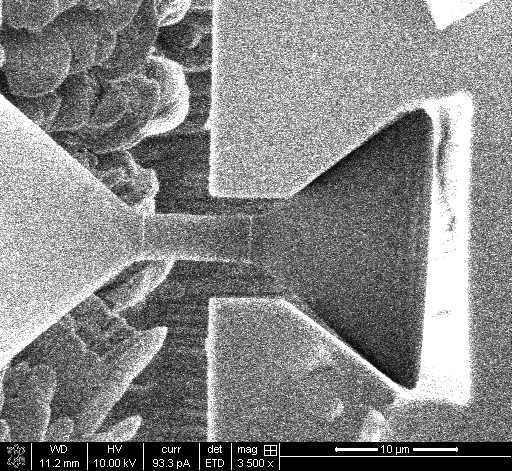

In [5]:
disp(img1)

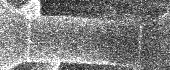

In [ ]:
#crop
disp(img1[200:270, 100:270])

def crop(img):
    return img[200:270, 100:270]

uint16
[[314 320 354 ... 260 294 344]
 [452 316 184 ... 366 260 438]
 [436 406 150 ... 358 304 510]
 ...
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]]


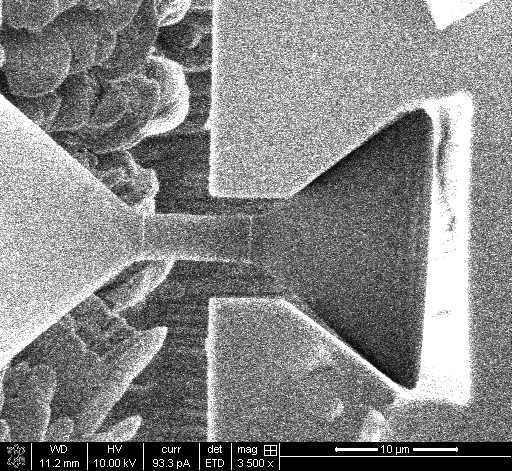

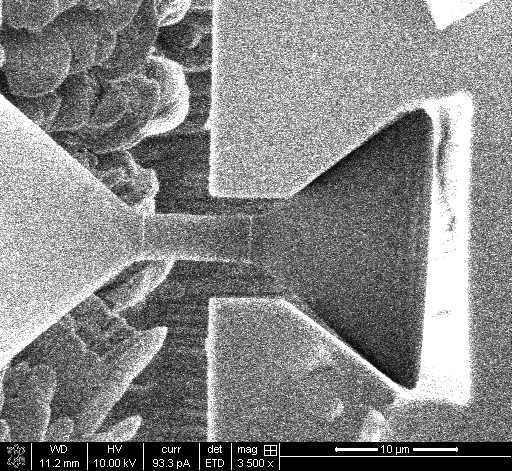

In [ ]:
img_sum = imgs[1].copy()
for i in range(1, 2):
    img_sum += imgs[i]

print(img_sum.dtype)
print(img_sum)

disp(to_u8(imgs[0]))
disp(to_u8(imgs[0] + imgs[0]))

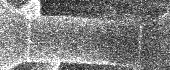

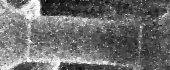

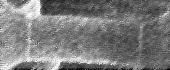

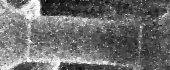

In [ ]:
#deblur with median or something
#disp(ski.filters.butterworth(crop(img1), cutoff_frequency_ratio=0.5, high_pass = False))
#Or maybe we could mess with the fourier transform and only get frequencies that are moving horizontally

#nah, tv filter
disp(crop(img1))
disp_float(denoise_tv_chambolle(crop(img1), weight=0.05, max_num_iter=2000))
disp_float(denoise_bilateral(crop(img1), win_size = 5, sigma_spatial=1))

def bi_dn(img):
    return denoise_bilateral(img1, win_size = 5, sigma_spatial=1)

disp_float(denoise_tv_chambolle(crop(img1), weight=0.05, max_num_iter=2000))

#detect then blur?

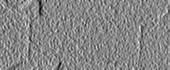

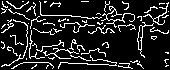

In [ ]:
#sobel
disp_float(ski.filters.sobel_v(crop(img1)))
disp_bool(ski.feature.canny(denoise_tv_chambolle(crop(img1)), sigma=1))


In [ ]:
#paste

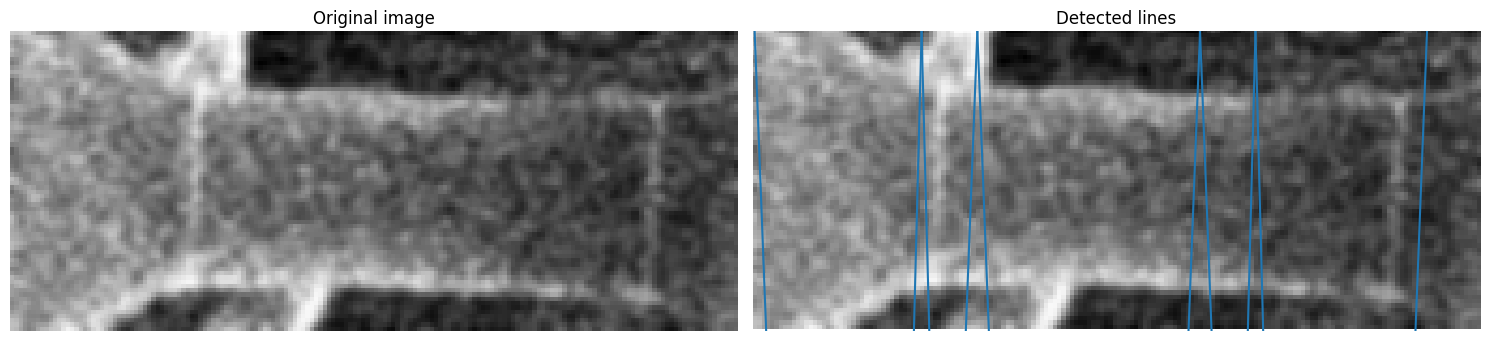

In [ ]:
import numpy as np

from skimage.transform import hough_line, hough_line_peaks
from skimage.feature import canny
from skimage.draw import line as draw_line
from skimage import data

import matplotlib.pyplot as plt
from matplotlib import cm

img1=ski.filters.gaussian(crop(get_file(1)))

# Classic straight-line Hough transform
# Set a precision of 0.5 degree.
tested_angles = np.linspace(-np.pi / 64, np.pi / 64, 360, endpoint=False)
h, theta, d = hough_line(img1, theta=tested_angles)

# Generating figure 1
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes.ravel()

ax[0].imshow(img1, cmap=cm.gray)
ax[0].set_title('Original image')
ax[0].set_axis_off()


ax[1].imshow(img1, cmap=cm.gray)
ax[1].set_ylim((img1.shape[0], 0))
ax[1].set_axis_off()
ax[1].set_title('Detected lines')

for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=10)):
    (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
    ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

plt.tight_layout()
plt.show()

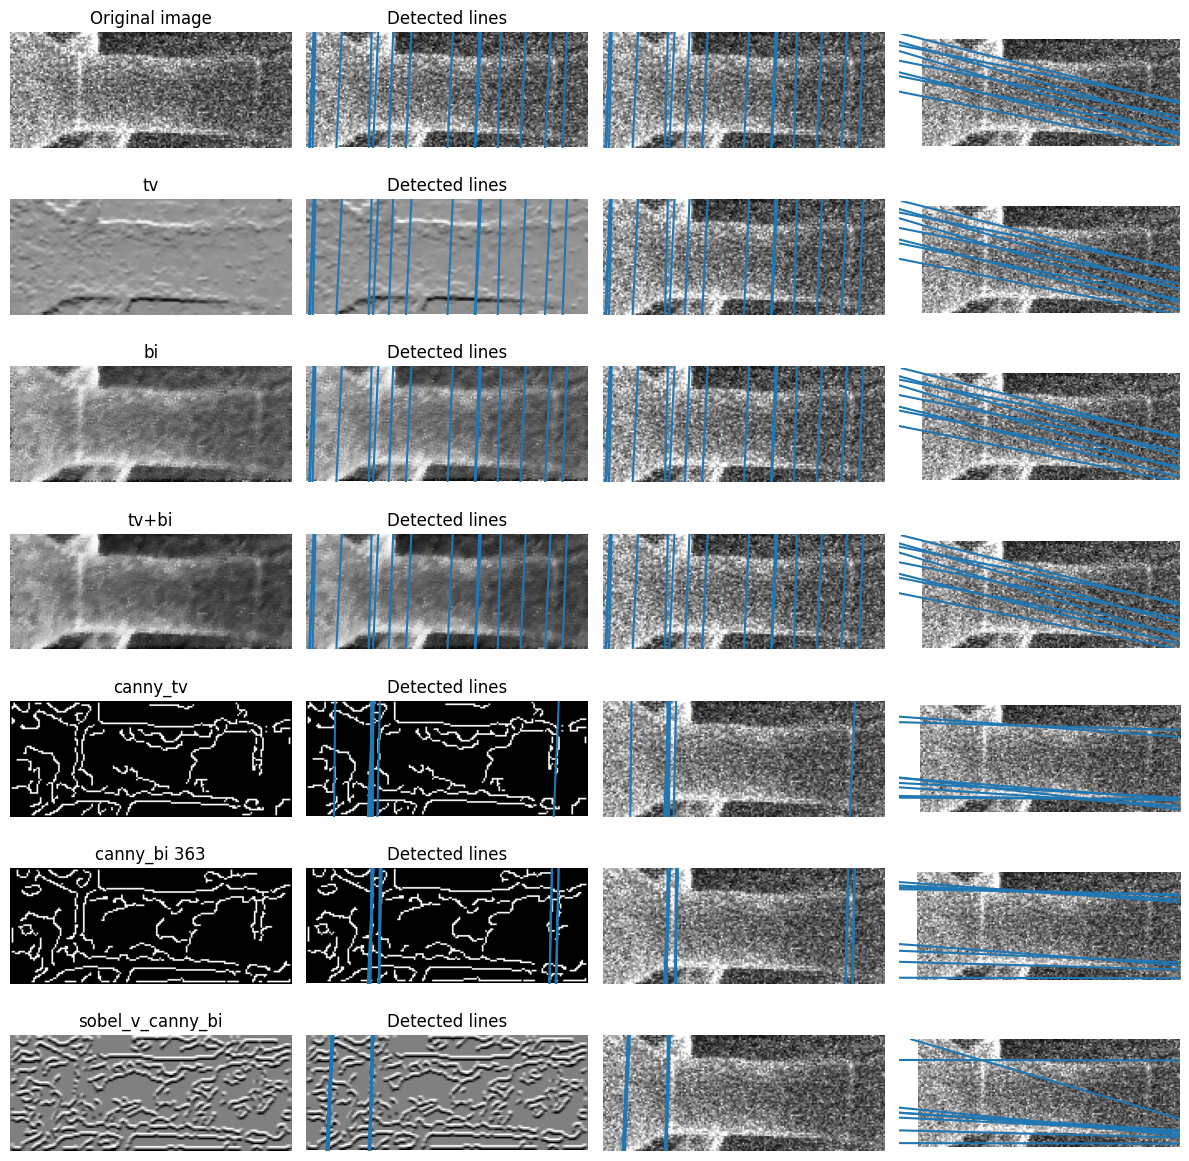

In [ ]:
import numpy as np

from skimage.transform import hough_line, hough_line_peaks
from skimage.feature import canny
from skimage.draw import line as draw_line
from skimage import data

import matplotlib.pyplot as plt
from matplotlib import cm

import random


num = random.randint(1, 610)
img1=(crop(get_file(34)))

# Classic straight-line Hough transform
# Set a precision of 0.5 degree.


# Generating figure 1
fig, axes = plt.subplots(7, 4, figsize=(12, 12))

def add_figures(img, ax, name='Original image'):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(img, theta=tested_angles)

    ax[0].imshow(img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()


    ax[1].imshow(img, cmap=cm.gray)
    ax[1].set_ylim((img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

    ax[2].imshow(img1, cmap=cm.gray)
    ax[2].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
            #print(x0, y0, np.tan(angle + np.pi / 2))

    tested_angles = np.linspace(-np.pi/2, -np.pi / 2.5, 360, endpoint=False)
    h, theta, d = hough_line(img, theta=tested_angles)

    ax[3].imshow(img1, cmap=cm.gray)
    ax[3].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=8)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[3].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
        
add_figures(img1, axes[0])
add_figures(ski.filters.sobel_h(denoise_tv_chambolle(img1)), axes[1], "tv")
add_figures(bi_dn(img1), axes[2], "bi")
add_figures(denoise_tv_chambolle(img1) + bi_dn(img1), axes[3], "tv+bi")

add_figures(ski.feature.canny(denoise_tv_chambolle(img1), sigma=1.3), axes[4], "canny_tv")
add_figures(ski.feature.canny(bi_dn(img1), sigma=1.7), axes[5], f"canny_bi {num}")
add_figures(ski.filters.sobel_h(ski.feature.canny(bi_dn(img1), sigma=1.3)), axes[6], "sobel_v_canny_bi")




plt.tight_layout()
plt.show()

In [ ]:
#Nope, canny_bi absolutly crushes line detection
#So now we just need to 1) average and find the 2 lines
#                       2) draw smaller lines
#                       3) convert to larger image coords

In [ ]:
def average_out_lines(img, thresh = 10):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(img, theta=tested_angles)

    existing_lines = []

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        averaged= False

        for line in existing_lines:
            if (abs(line[0]-x0) < thresh):
                line[0] = (line[3] * line[0] + x0)/(line[3]+1)
                line[1] = line[1] + y0
                line[2] = line[2] + np.tan(angle + np.pi / 2)
                line[3]+=1
                averaged = True
                break
        if not averaged:
            existing_lines.insert(0, [x0, y0, np.tan(angle + np.pi / 2), 1])

    for line in existing_lines:
        line[1]/=line[3]
        line[2]/=line[3]

    existing_lines.sort(key=(lambda a : a[3]), reverse=True)

    return existing_lines[:2]

def average_out_lines_h(img, thresh = 10):
    tested_angles = np.linspace(-np.pi/2, -np.pi / 2.5, 360, endpoint=False)
    h, theta, d = hough_line(img, theta=tested_angles)

    existing_lines = []

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=8)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        averaged= False

        for line in existing_lines:
            if (abs(line[1]-y0) < thresh):
                line[0] = line[0] + x0
                line[1] = ((line[1]*line[3]) + y0)/(line[3]+1)
                line[2] = line[2] + np.tan(angle + np.pi / 2)
                line[3]+=1
                averaged = True
                break
        if not averaged:
            existing_lines.insert(0, [x0, y0, np.tan(angle + np.pi / 2), 1])

    for line in existing_lines:
        line[0]/=line[3]
        line[2]/=line[3]

    existing_lines.sort(key=(lambda a : a[3]), reverse=True)

    return existing_lines[:2]

[[142 230 223 ...  77  60  77]
 [225 178 141 ... 123 148 106]
 [178 155 167 ... 164 132  97]
 ...
 [232 143 196 ... 132 138 112]
 [131  99 209 ... 109  68 114]
 [147 189 207 ... 176 100 161]]
2


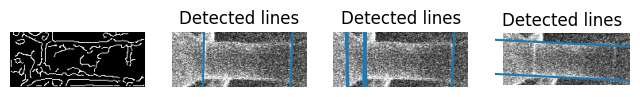

In [ ]:

print(img1)
fig, ax = plt.subplots(1, 4, figsize=(8, 12))

img_bd_dn_cn = ski.feature.canny(bi_dn(img1), sigma=1.7)
img_tv_cn = ski.feature.canny(denoise_tv_chambolle(img1), sigma=1.3)

ax[0].imshow(img_bd_dn_cn, cmap=cm.gray)
ax[0].set_axis_off()


ax[1].imshow(img1, cmap=cm.gray)
ax[1].set_ylim((img1.shape[0], 0))
ax[1].set_axis_off()
ax[1].set_title('Detected lines')

ax[2].imshow(img1, cmap=cm.gray)
ax[2].set_ylim((img1.shape[0], 0))
ax[2].set_axis_off()
ax[2].set_title('Detected lines')

print(len(average_out_lines(img_tv_cn, 100)))

for x0, y0, angle, _ in average_out_lines(img_tv_cn, 15):
    ax[1].axline((x0, y0), slope=angle)

tested_angles = np.linspace(-np.pi / 64, np.pi / 64, 360, endpoint=False)
h, theta, d = hough_line(img_tv_cn, theta=tested_angles)

for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
    (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
    ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

ax[3].imshow(img1, cmap=cm.gray)
ax[3].set_ylim((img1.shape[0], 0))
ax[3].set_axis_off()
ax[3].set_title('Detected lines')

for x0, y0, angle, _ in average_out_lines_h(img_tv_cn, 10):
    ax[3].axline((x0, y0), slope=angle) 

In [ ]:
def intersection(x0, y0, theta0, x1, y1, theta1):
    x = (y1-y0 + theta0*x0 - theta1*x1)/(theta0-theta1)
    y = theta0*(x-x0) + y0
    return (x,y)

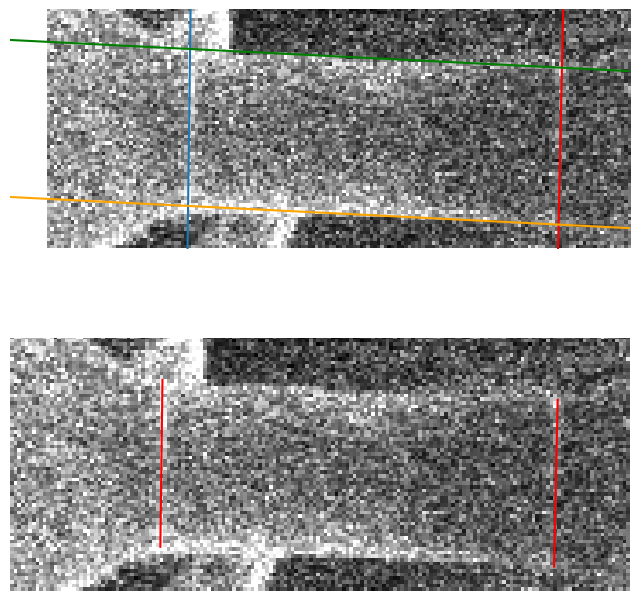

In [ ]:
vert_lines = average_out_lines(img_bd_dn_cn, 10)
hori_lines = average_out_lines_h(img_tv_cn, 10)

vert_lines.sort(key=(lambda a : a[0]))
hori_lines.sort(key=(lambda a : a[1]))


left = vert_lines[0]
right = vert_lines[1]
top = hori_lines[0]
bot = hori_lines[1]

upper_right = intersection(*right[:3], *top[:3])
upper_left = intersection(*left[:3], *top[:3])
lower_left = intersection(*left[:3], *bot[:3])
lower_right = intersection(*right[:3], *bot[:3])

fig, ax = plt.subplots(2, 1, figsize=(8, 8))
ax[0].imshow(img1, cmap=cm.gray)
ax[0].set_ylim((img1.shape[0], 0))
ax[0].set_axis_off()

ax[0].axline((left[0], left[1]), slope=left[2])
ax[0].axline((right[0], right[1]), slope=right[2], color="red")
ax[0].axline((top[0], top[1]), slope=top[2], color="green")
ax[0].axline((bot[0], bot[1]), slope=bot[2], color="orange")

ax[1].imshow(img1, cmap=cm.gray)
ax[1].set_ylim((img1.shape[0], 0))
ax[1].set_axis_off()
ax[1].plot((upper_right[0], lower_right[0]), (upper_right[1], lower_right[1]), color ="red")
ax[1].plot((upper_left[0], lower_left[0]), (upper_left[1], lower_left[1]), color ="red")

In [ ]:
#I'm ususally within 2-4 px of the line 
#Worse of maybe 7

#anyways, we draw onto image time
"""
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
img=get_file(num)
ax.imshow(img, cmap=cm.gray)
ax.set_ylim((img.shape[0], 0))
ax.set_axis_off()

x_offset=100
y_offset=210

#ax.plot((upper_right[0]+x_offset, lower_right[0]+x_offset), (upper_right[1]+y_offset, lower_right[1]+y_offset), color ="red")
#ax.plot((upper_left[0]+x_offset, lower_left[0]+x_offset), (upper_left[1]+y_offset, lower_left[1]+y_offset), color ="red")

fig.savefig("lol.png")
"""

'\nfig, ax = plt.subplots(1, 1, figsize=(8, 8))\nimg=get_file(num)\nax.imshow(img, cmap=cm.gray)\nax.set_ylim((img.shape[0], 0))\nax.set_axis_off()\n\nx_offset=100\ny_offset=210\n\n#ax.plot((upper_right[0]+x_offset, lower_right[0]+x_offset), (upper_right[1]+y_offset, lower_right[1]+y_offset), color ="red")\n#ax.plot((upper_left[0]+x_offset, lower_left[0]+x_offset), (upper_left[1]+y_offset, lower_left[1]+y_offset), color ="red")\n\nfig.savefig("lol.png")\n'

In [ ]:
for i in range(1,3):
    img1=(crop(get_file(i)))

    img_bd_dn_cn = ski.feature.canny(bi_dn(img1), sigma=1.7)
    img_tv_cn = ski.feature.canny(denoise_tv_chambolle(img1), sigma=1.3)

    vert_lines = average_out_lines(img_bd_dn_cn, 10)
    hori_lines = average_out_lines_h(img_tv_cn, 10)

    vert_lines.sort(key=(lambda a : a[0]))
    hori_lines.sort(key=(lambda a : a[1]))
    print(vert_lines)

    try:
        left = vert_lines[0]
        right = vert_lines[1]
        top = hori_lines[0]
        bot = hori_lines[1]
    except:
        print(i)
        break

    upper_right = intersection(*right[:3], *top[:3])
    upper_left = intersection(*left[:3], *top[:3])
    lower_left = intersection(*left[:3], *bot[:3])
    lower_right = intersection(*right[:3], *bot[:3])

    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    img=get_file(i)
    ax.imshow(img, cmap=cm.gray)
    ax.set_ylim((img.shape[0], 0))
    ax.set_axis_off()

    x_offset=100
    y_offset=200

    ax.plot((upper_right[0]+x_offset, lower_right[0]+x_offset), (upper_right[1]+y_offset, lower_right[1]+y_offset), color ="red")
    ax.plot((upper_left[0]+x_offset, lower_left[0]+x_offset), (upper_left[1]+y_offset, lower_left[1]+y_offset), color ="red")

    fig.savefig(f"{i}.png")
    plt.close()

[[np.float64(46.98432367934418), np.float64(1.032638548361669), np.float64(-79.6823481530338), 8], [np.float64(153.19037938219745), np.float64(4.994237081084821), np.float64(-40.3607282198402), 7]]
[[np.float64(41.64707949750524), np.float64(1.1570414318782098), np.float64(-52.57277300611148), 6], [np.float64(149.14438809094978), np.float64(4.226386095765365), np.float64(-70.51942951064244), 9]]


In [ ]:
#Find indexes to highlight


In [ ]:
def bi_fy(img):
    return img/2 + to_u8(bi_dn(img))/2

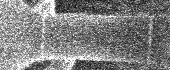

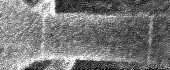

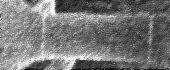

In [ ]:
disp(img1)
disp_float(bi_fy(img1))
disp_float(bi_fy(bi_fy(img1)))

In [ ]:
img1=(crop(get_file(i)))

img_bd_dn_cn = ski.feature.canny(bi_dn(img1), sigma=1.7)
img_tv_cn = ski.feature.canny(denoise_tv_chambolle(img1), sigma=1.3)

vert_lines_bd_dn = average_out_lines(img_bd_dn_cn, 10)
hori_lines_bd_dn = average_out_lines_h(img_bd_dn_cn, 10)
vert_lines_tv = average_out_lines(img_tv_cn, 10)
hori_lines_tv = average_out_lines_h(img_tv_cn, 10)

vert_lines_bd_dn.sort(key=(lambda a : a[0]))

fig, ax = plt.subplots(2, 1, figsize=(8, 8))
ax[0].imshow(img1, cmap=cm.gray)
ax[0].set_ylim((img1.shape[0], 0))
ax[0].set_axis_off()

ax[0].axline((left[0], left[1]), slope=left[2], color="red")
ax[0].axline((right[0], right[1]), slope=right[2], color="red")
ax[0].axline((top[0], top[1]), slope=top[2], color="red")
ax[0].axline((bot[0], bot[1]), slope=bot[2], color="red")

ax[1].imshow(img1, cmap=cm.gray)
ax[1].set_ylim((img1.shape[0], 0))
ax[1].set_axis_off()
ax[1].plot((upper_right[0], lower_right[0]), (upper_right[1], lower_right[1]), color ="red")
ax[1].plot((upper_left[0], lower_left[0]), (upper_left[1], lower_left[1]), color ="red")

In [ ]:
#update, use both methods to get the lines

def get_points(i):
    img1=(crop(get_file(i)))

    img_bd_dn_cn = ski.feature.canny(bi_dn(img1), sigma=1.7)
    img_tv_cn = ski.feature.canny(denoise_tv_chambolle(img1), sigma=1.3)

    vert_lines_bd_dn = average_out_lines(img_bd_dn_cn, 10)
    hori_lines_bd_dn = average_out_lines_h(img_bd_dn_cn, 10)
    vert_lines_tv = average_out_lines(img_tv_cn, 10)
    hori_lines_tv = average_out_lines_h(img_tv_cn, 10)

    vert_lines.sort(key=(lambda a : a[0]))
    hori_lines.sort(key=(lambda a : a[1]))
    #print(vert_lines)

    try:
        left = vert_lines[0]
        right = vert_lines[1]
        top = hori_lines[0]
        bot = hori_lines[1]
    except:
        print(i)

    upper_right = intersection(*right[:3], *top[:3])
    upper_left = intersection(*left[:3], *top[:3])
    lower_left = intersection(*left[:3], *bot[:3])
    lower_right = intersection(*right[:3], *bot[:3])

    return [upper_right, upper_left, lower_right, lower_left]

In [ ]:
#I'm too lazy to manually tune so we'll use a CNN with the frames that work and hopefully that will solve the problem
# Ok, I'll make the database first

import pandas as pd
import itertools

#we'll go with this for now
good_images = itertools.chain(range(2,25), range(26, 30), range(31, 44), range(45, 54), range(55, 114), range(115, 173), range(174, 185))

img_and_points = [[crop(get_file(i))] + get_points(i) for i in good_images]

data = {
    "Images" : [l[0] for l in img_and_points],
    "upper_right_x" : [l[1][0] for l in img_and_points],
    "upper_right_y" : [l[1][1] for l in img_and_points],
    "upper_left_x" : [l[2][0] for l in img_and_points],
    "upper_left_y" : [l[2][1] for l in img_and_points],
    "lower_right_x" : [l[3][0] for l in img_and_points],
    "lower_right_y" : [l[3][1] for l in img_and_points],
    "lower_left_x" : [l[4][0] for l in img_and_points],
    "lower_left_y" : [l[4][1] for l in img_and_points]
}


In [ ]:
from sklearn.model_selection import train_test_split

X = data["Images"]
y = data["upper_right_x"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train)

[array([[248, 208, 125, ...,  62, 103,  64],
       [255, 194, 200, ...,  97,  82,  84],
       [123, 161, 121, ..., 106,  98, 121],
       ...,
       [180, 133, 224, ..., 151, 117, 113],
       [204, 139, 180, ...,  71,  90, 140],
       [180, 213, 181, ..., 215, 211, 163]], shape=(70, 170), dtype=uint8), array([[153, 253, 151, ...,  95, 100,  90],
       [234, 176, 159, ..., 101, 136, 130],
       [195, 218, 180, ...,  50,  35,  57],
       ...,
       [148, 114, 130, ..., 124,  74,  67],
       [171, 192, 109, ..., 103, 153, 169],
       [167, 255, 255, ..., 173, 176, 111]], shape=(70, 170), dtype=uint8), array([[135, 163, 191, ...,  81,  77, 132],
       [146, 155, 191, ..., 104,  83, 146],
       [170, 229, 215, ..., 128, 147,  71],
       ...,
       [185, 185, 112, ..., 156, 143,  83],
       [255, 232, 158, ...,  85, 115, 144],
       [131, 170, 158, ..., 110,  86, 110]], shape=(70, 170), dtype=uint8), array([[194, 177, 248, ..., 110,  53, 107],
       [176, 127, 201, ...,  75

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class ImageDataset(Dataset):
    def __init__(self, features, targets):
        self.X = torch.tensor(features, dtype=torch.uint8)
        self.y = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = ImageDataset(X_train, y_train)
test_dataset = ImageDataset(X_test, y_test)

test_dataset.__len__()
test_dataset[35]

/tmp/ipykernel_37369/2556626497.py:6: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  self.X = torch.tensor(features, dtype=torch.uint8)


(tensor([[155, 187, 160,  ...,  60, 102,  54],
         [226, 255, 105,  ...,  57,  90, 134],
         [105, 155, 232,  ..., 144,  94,  61],
         ...,
         [162, 163, 219,  ...,  72, 113, 126],
         [206, 211, 214,  ..., 126, 100, 127],
         [159, 183, 200,  ...,  89,  62, 157]], dtype=torch.uint8),
 tensor(148.9900))

In [ ]:
import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5,), (0.5,))
])

batch_size=4

trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size,
                                          shuffle=True, num_workers=1)

testloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size,
                                          shuffle=True, num_workers=1)

In [ ]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
print(dataiter)
next(dataiter)

#images, labels = next(dataiter)

# show images
#imshow(torchvision.utils.make_grid(images))

Traceback (most recent call last):
  File "/home/trigger/miniconda3/envs/badApple/lib/python3.14/multiprocessing/forkserver.py", line 340, in main
    code = _serve_one(child_r, fds,
                      unused_fds,
                      old_handlers)
  File "/home/trigger/miniconda3/envs/badApple/lib/python3.14/multiprocessing/forkserver.py", line 380, in _serve_one
    code = spawn._main(child_r, parent_sentinel)
  File "/home/trigger/miniconda3/envs/badApple/lib/python3.14/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
AttributeError: module '__main__' has no attribute 'ImageDataset'


RuntimeError: DataLoader worker (pid(s) 38370) exited unexpectedly